# 1 · BDD100K preparation, EDA and **offline** preprocessing

Execute top to bottom before notebook 2. This notebook reads actual BDD detection
labels, uses the official BDD/Scalabel and Ultralytics converters, and materializes
only the enabled variants. Raw images stay untouched. Nothing here trains a model.

**Study boundary:** official train supplies train/tune. Official val supplies test.
The executed small test subset is integration evidence, **not** an untouched final
research holdout. Its IDs are recorded in `test_exposure.json` and excluded from a
future full study, along with the earlier CLI pilot's 80 test IDs. Do not choose
recipes or models using these test scores; calibrate on train-derived tune only.

In [1]:
import importlib.metadata as md
import inspect
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from vehicle_detection.common import digest, read_image, read_json, write_json
from vehicle_detection.data import ALIASES, CLASSES, choose_splits, convert_labels, scan_bdd
from vehicle_detection.offline import export_variant, verify_alignment
from vehicle_detection.preprocess import apply_recipe, quality, validate_recipes

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
DATA_ROOT = ROOT / "data/bdd100k"
MODE = "pilot"  # 'full' selects all eligible examples; assess disk space first.
SEED = 2026
LIMITS = (
    {"train": 64, "tune": 16, "test": 16}
    if MODE == "pilot"
    else dict.fromkeys(["train", "tune", "test"])
)
RUN_ROOT = ROOT / "runs" / f"notebook-{MODE}"
ENABLED_VARIANTS = ["raw", "gamma"]  # Materialize only these; add candidates after inspecting tune.
SOURCE_BOX_CONVENTION = "continuous"  # Explicit x2-x1 extents for this 2018-label study.
RECIPES = {
    "raw": {},
    "gamma": {"gamma": 0.65},
    "clahe": {"clip_limit": 2.0, "grid_size": 8},
    "denoise": {"strength": 5.0},
    "sharpen": {"amount": 0.5, "sigma": 1.0},
    "adaptive": {
        "brightness_below": 0.28,
        "contrast_below": 0.16,
        "noise_above": 0.035,
        "sharpness_min": 10.0,
        "sharpness_below": 100.0,
        "max_filters": 2,
    },
}
validate_recipes(RECIPES)
assert "raw" in ENABLED_VARIANTS and set(ENABLED_VARIANTS) <= RECIPES.keys()
RUN_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})
display(
    pd.Series(
        {
            p: md.version(p)
            for p in [
                "bdd100k",
                "scalabel",
                "pydantic",
                "ultralytics",
                "numpy",
                "opencv-python",
                "pandas",
            ]
        },
        name="installed version",
    )
)

bdd100k              1.0.1
scalabel             0.3.1
pydantic           1.10.27
ultralytics        8.4.198
numpy                2.4.6
opencv-python    4.14.0.94
pandas               2.3.3
Name: installed version, dtype: object

## Discover the real schema and canonical images

The local Kaggle extraction also contains 10k/segmentation copies. We deliberately
index **one canonical `images/100k` tree** and stream the split JSONs (the train
file is about 1.45 GB). Supported containers are the BDD 2018 frame list and modern
Scalabel `{frames: [...]}`. Missing files are counted; missing detection labels,
ambiguous paths and duplicate IDs fail. Person/rider/sign/light/polygon labels are
excluded from this six-vehicle study. Occluded/truncated vehicle boxes are kept.
The actual execution below verifies the 2018 file; a 2020 container is covered by
a small fixture test, **not** claimed as a separate real-data run.

In [2]:
records, audit, annotation_sources = scan_bdd(DATA_ROOT)
print("Detection frames with matching images:", len(records))
display(pd.DataFrame(annotation_sources).T)
display(pd.Series(audit, name="discovery audit"))
print("Frame fields:", list(records[0]))
print("Actual first retained box label:", records[0]["labels"][0])

Detection frames with matching images: 79863


,path,sha256,schema
train,/mnt/d/Projects/vehicle-detection/data/bdd100k...,c1998792e385fd79213187576ca07d5249563d0ab83ae9...,item
val,/mnt/d/Projects/vehicle-detection/data/bdd100k...,c835be652f0c002897be51e74deedd16a1dcee0b7230f1...,item


frames:train                              69863
ignored_nonvehicle_or_polygon_labels    1345450
frames:val                                10000
Name: discovery audit, dtype: int64

Frame fields: ['id', 'name', 'path', 'official_split', 'group', 'attributes', 'labels']
Actual first retained box label: {'category': 'car', 'attributes': {'occluded': False, 'truncated': False, 'trafficLightColor': 'none'}, 'manualShape': True, 'manualAttributes': True, 'box2d': {'x1': 45.240919, 'y1': 254.530367, 'x2': 357.805838, 'y2': 487.906215}, 'id': 4}


split,train,val
vehicle box counts,,
car,713211,102506
truck,29971,4245
bus,11672,1597
train,136,15
motorcycle,3002,452
bicycle,7210,1007


split,train,val
images containing class,,
car,69072,9879
truck,18890,2689
bus,8993,1242
train,105,14
motorcycle,2284,334
bicycle,4343,578


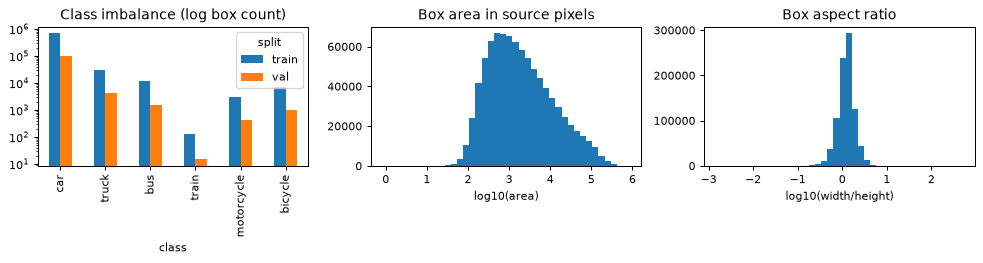

In [3]:
images = pd.DataFrame(
    [
        {
            "id": r["id"],
            "split": r["official_split"],
            **{k: r["attributes"].get(k, "unknown") for k in ["weather", "timeofday", "scene"]},
        }
        for r in records
    ]
)
boxes = pd.DataFrame(
    [
        {
            "id": r["id"],
            "split": r["official_split"],
            "class": ALIASES.get(label["category"], label["category"]),
            "width": label["box2d"]["x2"] - label["box2d"]["x1"],
            "height": label["box2d"]["y2"] - label["box2d"]["y1"],
        }
        for r in records
        for label in r["labels"]
    ]
)
boxes["area"] = boxes.width * boxes.height
boxes["aspect_ratio"] = boxes.width / boxes.height
counts = pd.crosstab(boxes["class"], boxes["split"]).reindex(CLASSES, fill_value=0)
display(counts.rename_axis("vehicle box counts"))
display(
    boxes.groupby(["split", "class"])
    .id.nunique()
    .unstack(0)
    .reindex(CLASSES)
    .fillna(0)
    .astype(int)
    .rename_axis("images containing class")
)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
counts.plot.bar(ax=axes[0], logy=True, title="Class imbalance (log box count)")
axes[1].hist(np.log10(boxes.loc[boxes.area > 0, "area"]), bins=40)
axes[1].set(title="Box area in source pixels", xlabel="log10(area)")
axes[2].hist(np.log10(boxes.loc[boxes.aspect_ratio > 0, "aspect_ratio"]), bins=40)
axes[2].set(title="Box aspect ratio", xlabel="log10(width/height)")
fig.tight_layout()
plt.show()

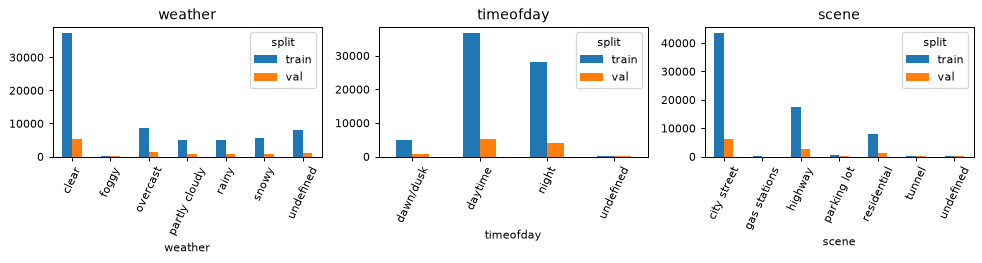

,brightness,contrast,sharpness,noise,black_fraction,white_fraction
count,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000
mean,0.2813,0.1827,562.7849,0.0007,0.0394,0.0041
std,0.1579,0.0626,380.3018,0.0019,0.0875,0.0098
min,0.0440,0.0609,40.3137,0.0000,0.0000,0.0000
25%,0.1159,0.1279,248.7247,0.0000,0.0000,0.0001
50%,0.3504,0.1969,452.9902,0.0000,0.0012,0.0011
75%,0.4212,0.2286,835.8628,0.0000,0.0212,0.0036
max,0.6345,0.3130,1507.5540,0.0058,0.4339,0.0607


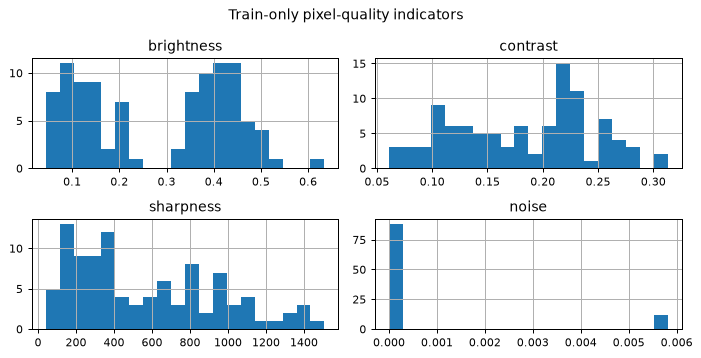

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, key in zip(axes, ["weather", "timeofday", "scene"], strict=True):
    pd.crosstab(images[key], images.split).plot.bar(ax=ax, title=key)
    ax.tick_params(axis="x", rotation=65)
fig.tight_layout()
plt.show()
train_records = [r for r in records if r["official_split"] == "train"]
sampled = pd.Series(train_records).sample(min(100, len(train_records)), random_state=SEED).tolist()
quality_table = pd.DataFrame([{"id": r["id"], **quality(read_image(r["path"]))} for r in sampled])
display(quality_table.describe().round(4))
quality_table[["brightness", "contrast", "sharpness", "noise"]].hist(bins=20, figsize=(8, 4))
plt.suptitle("Train-only pixel-quality indicators")
plt.tight_layout()
plt.show()

Quality is measured at a maximum 512-pixel side: grayscale mean and standard
deviation divided by 255, Laplacian variance, and median absolute residual against
a 3×3 median filter divided by 0.6745×255. Texture can affect these indicators.
Adaptive thresholds are transparent **uncalibrated heuristics**. A bounded
sequence (maximum two filters) or skip is chosen from pixels, never BDD metadata.
No filter changes image coordinates, and sharpening cannot recover lost blur detail.

Quality diagnostics sample official train only; recipe previews below use train-derived tune. Neither is calibrated from official-val test pixels.

In [5]:
exposure_path = ROOT / "notebooks/test_exposure.json"
exposure = read_json(exposure_path)
excluded = set(exposure["legacy_pilot"])
if MODE == "full":
    excluded.update(exposure["notebook_pilot"])
partitions = choose_splits(records, SEED, LIMITS, excluded_test_ids=excluded)
selection = {s: [r["id"] for r in rows] for s, rows in partitions.items()}
selection_id = digest(
    [(s, r["id"], r["sha256"], r["labels"]) for s, rows in partitions.items() for r in rows]
)
study = {
    "seed": SEED,
    "limits": LIMITS,
    "selection_id": selection_id,
    "splits": selection,
    "excluded_test_ids": sorted(excluded),
    "box_convention": SOURCE_BOX_CONVENTION,
    "annotation_sources": annotation_sources,
}
study_path = RUN_ROOT / "selection.json"
if study_path.exists() and read_json(study_path) != study:
    raise ValueError("Selection/config changed: use a fresh RUN_ROOT")
write_json(study_path, study)
if MODE == "pilot":
    exposure["notebook_pilot"] = sorted(set(exposure["notebook_pilot"]) | set(selection["test"]))
    write_json(exposure_path, exposure)
display(pd.Series({s: len(v) for s, v in partitions.items()}, name="selected images"))
print(
    "Disjoint ID/video-group/content hashes checked; excluded previously exposed test IDs:",
    len(excluded),
)

train    64
tune     16
test     16
Name: selected images, dtype: int64

Disjoint ID/video-group/content hashes checked; excluded previously exposed test IDs: 80


## Official conversion, explicit coordinate bridge, exhaustive selected-box checks

The pinned **BDD100K 1.0.1** API uses `bdd100k_to_scalabel` for its official
`bike→bicycle`, `motor→motorcycle` mapping, then the detection converter imported
by `bdd100k.label.to_coco`. It accepts the local 2018 list through Scalabel's
validated loader. Only selected box labels are passed, avoiding 2018 lane polygons
and loading the entire giant JSON. Actual decoded dimensions are attached per frame.

**Version incompatibility:** Scalabel **0.3.1** computes `x2-x1+1`. This study uses
continuous BDD2018 extents `x2-x1`; the minimal adapter subtracts that added one
from official COCO width/height and recomputes area. `inclusive` can be selected
explicitly for a dataset defined that way. No clipping/scaling is performed.
The six official COCO category IDs are remapped to 1–6 by name, then native
`convert_coco(..., cls91to80=False)` makes YOLO IDs 0–5. Native crowd/ignored
annotations are excluded and identical boxes are deduplicated. Every selected
YOLO box is decoded and checked against its source to **0.01 pixel**; IDs/bounds
must be valid. Labels with no vehicles remain valid empty files.

References: [BDD toolkit](https://github.com/bdd100k/bdd100k),
[Scalabel converter](https://github.com/scalabel/scalabel/blob/v0.3.1/scalabel/label/transforms.py),
[Ultralytics converter](https://docs.ultralytics.com/reference/data/converter/).

In [6]:
from bdd100k.label.to_coco import scalabel2coco_detection
from scalabel.label.transforms import box2d_to_bbox

print(inspect.getsource(box2d_to_bbox))
print("Official detection API:", inspect.signature(scalabel2coco_detection))
conversion = convert_labels(partitions, RUN_ROOT / "conversion", SOURCE_BOX_CONVENTION)
display(conversion)
display(pd.DataFrame({"class": CLASSES, "COCO ID": range(1, 7), "YOLO ID": range(6)}))

def box2d_to_bbox(box2d: Box2D) -> List[float]:
    """Convert Scalabel Box2D into COCO bbox."""
    width = box2d.x2 - box2d.x1 + 1
    height = box2d.y2 - box2d.y1 + 1
    return [box2d.x1, box2d.y1, width, height]

Official detection API: (frames: List[scalabel.label.typing.Frame], config: scalabel.label.typing.Config) -> scalabel.label.coco_typing.GtType


  0%|          | 0/64 [00:00<?, ?it/s]

100%|██████████| 64/64 [00:00<00:00, 238397.39it/s]

  0%|          | 0/64 [00:00<?, ?it/s]

100%|██████████| 64/64 [00:00<00:00, 81940.00it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

... (11 outputs left out)

Annotations /mnt/d/Projects/vehicle-detection/runs/notebook-pilot/conversion/coco/tune.json: 100% ━━━━━━━━━━━━ 16/16 259.8it/s 0.1s

COCO data converted successfully.
Results saved to /mnt/d/Projects/vehicle-detection/runs/notebook-pilot/conversion/tmp00cttcij/yolo


{'box_convention': 'continuous',
 'classes': ['car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle'],
 'coco_category_ids': [1, 2, 3, 4, 5, 6],
 'geometry_tolerance_pixels': 0.01,
 'versions': {'bdd100k': '1.0.1',
  'scalabel': '0.3.1',
  'ultralytics': '8.4.198'},
 'yolo_category_ids': [0, 1, 2, 3, 4, 5]}

,class,COCO ID,YOLO ID
0,car,1,0
1,truck,2,1
2,bus,3,2
3,train,4,3
4,motorcycle,5,4
5,bicycle,6,5


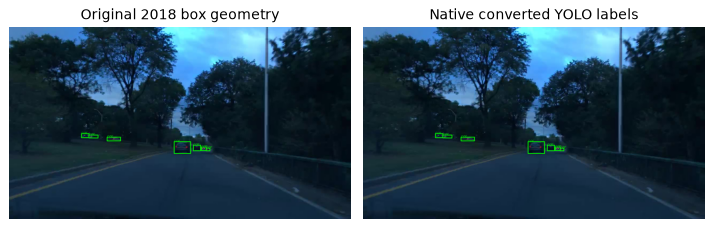

In [7]:
from ultralytics.utils.ops import xywh2xyxy


def overlay(image, record=None, label_path=None):
    image = image.copy()
    if record is not None:
        # Explicit key order; JSON dictionary order is not a coordinate contract.
        annotations = [
            (
                ALIASES.get(label["category"], label["category"]),
                [label["box2d"][k] for k in ["x1", "y1", "x2", "y2"]],
            )
            for label in record["labels"]
        ]
    else:
        text = Path(label_path).read_text().strip()
        labels = np.loadtxt(label_path, ndmin=2).reshape(-1, 5) if text else np.empty((0, 5))
        h, w = image.shape[:2]
        xyxy = xywh2xyxy(labels[:, 1:] * np.array([w, h, w, h]))
        annotations = [(CLASSES[int(row[0])], box) for row, box in zip(labels, xyxy, strict=True)]
    for name, box in annotations:
        x1, y1, x2, y2 = map(round, box)
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(image, name, (x1, max(12, y1)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


example = next(r for r in partitions["tune"] if r["labels"])
label_path = RUN_ROOT / "conversion/labels/tune" / f"{example['id']}.txt"
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(overlay(read_image(example["path"]), record=example))
axes[0].set_title("Original 2018 box geometry")
axes[1].imshow(overlay(read_image(example["path"]), label_path=label_path))
axes[1].set_title("Native converted YOLO labels")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

## Inspect recipes before materializing full datasets

These previews use only **tune** images. Raw/fixed/adaptive recipes are configurable
above; disabled variants generate no image copies. The adaptive policy may select
no filters. All processed exports are lossless PNG; raw exports link the original
JPEG bytes. Changing recipes or selected inputs requires a fresh output directory.

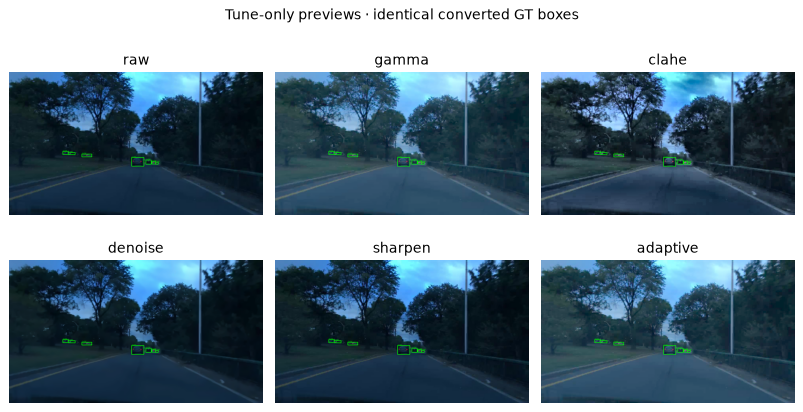

,decisions,brightness,contrast,sharpness,noise,black_fraction,white_fraction
variant,,,,,,,
raw,[],0.177083,0.168589,230.910397,0.0,0.00000,0.0
gamma,"[{'name': 'gamma', 'params': {'gamma': 0.65}}]",0.294526,0.167892,284.347735,0.0,0.00000,0.0
clahe,"[{'name': 'clahe', 'params': {'clip_limit': 2....",0.241920,0.178634,488.799759,0.0,0.00002,0.0
denoise,"[{'name': 'denoise', 'params': {'strength': 5....",0.175138,0.168675,210.437635,0.0,0.00000,0.0
sharpen,"[{'name': 'sharpen', 'params': {'amount': 0.5,...",0.177124,0.169024,312.400610,0.0,0.00000,0.0
adaptive,"[{'name': 'gamma', 'params': {'gamma': 0.65}}]",0.294526,0.167892,284.347735,0.0,0.00000,0.0


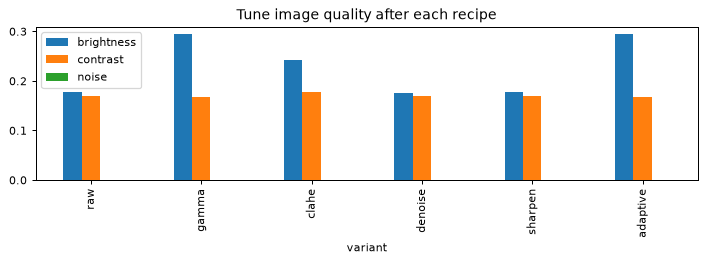

In [8]:
preview = read_image(example["path"])
fig, axes = plt.subplots(2, 3, figsize=(9, 5))
preview_rows = []
for ax, variant in zip(axes.flat, RECIPES, strict=True):
    processed, decisions, scores = apply_recipe(preview, variant, RECIPES)
    ax.imshow(overlay(processed, label_path=label_path))
    ax.axis("off")
    ax.set_title(variant)
    preview_rows.append({"variant": variant, "decisions": decisions, **quality(processed)})
fig.suptitle("Tune-only previews · identical converted GT boxes")
fig.tight_layout()
plt.show()
display(pd.DataFrame(preview_rows).set_index("variant"))
pd.DataFrame(preview_rows).set_index("variant")[["brightness", "contrast", "noise"]].plot.bar(
    figsize=(8, 3), title="Tune image quality after each recipe"
)
plt.tight_layout()
plt.show()

In [9]:
started = time.perf_counter()
tables = []
for variant in ENABLED_VARIANTS:
    table = export_variant(
        partitions, RUN_ROOT / "conversion", RUN_ROOT / "datasets" / variant, variant, RECIPES
    )
    tables.append(table)
    print(variant, "images:", len(table), "verified reused:", int(table.reused.sum()))
metadata = pd.concat(tables, ignore_index=True)
assert verify_alignment([RUN_ROOT / "datasets" / v for v in ENABLED_VARIANTS]) == sum(
    map(len, partitions.values())
)
metadata.to_csv(RUN_ROOT / "metadata.csv", index=False)
preparation = metadata.groupby("variant").agg(
    images=("id", "size"),
    preprocess_ms=("preprocess_ms", "sum"),
    preparation_ms=("preparation_ms", "sum"),
)
preparation["output_MiB"] = metadata.groupby("variant").apply(
    lambda d: sum(Path(p).stat().st_size for p in d.image if not Path(p).is_symlink()) / 2**20,
    include_groups=False,
)
preparation.to_csv(RUN_ROOT / "preparation_cost.csv")
display(preparation.round(3))
display(metadata[["id", "split", "variant", "decisions", "preprocess_ms", "reused"]].head(8))
print("Export wall seconds:", round(time.perf_counter() - started, 3))

raw images: 96 verified reused: 96


gamma images: 96 verified reused: 96


,images,preprocess_ms,preparation_ms,output_MiB
variant,,,,
gamma,96,357.632,4690.029,78.467
raw,96,313.007,1790.007,0.000


,id,split,variant,decisions,preprocess_ms,reused
0,02844a1f-c957e1c3,train,raw,[],3.457595,True
1,05b2c6da-e1425d1d,train,raw,[],3.087627,True
2,06f03de8-68743b21,train,raw,[],3.358890,True
3,077c3a83-95fa15a5,train,raw,[],3.085562,True
4,0dcd165f-6cc8189f,train,raw,[],3.209851,True
5,0ddab3e2-08017911,train,raw,[],3.617853,True
6,1127aff5-188de959,train,raw,[],3.279262,True
7,13796ade-b4bcd515,train,raw,[],3.157622,True


Export wall seconds: 10.735


Preparation time is an **offline cost**: read/decode, quality/filter work, image and
label writes, and output checks. `preprocess_ms` isolates feature/filter work.
The saved per-image times describe the original materialization, not a reuse run.
They must not be added to native validation speed and described as a measured online
end-to-end pipeline. Source hashing/discovery/conversion and reuse verification add
separate notebook wall time. Full PNG variants can use substantial disk space.

Exports use one compact JSONL metadata journal per variant and a CSV table, not
prediction shards. Recipe/input identities reject incompatible reruns. Completed
images/labels are hash-verified; missing/corrupt generated outputs can be repaired.
Unexpected symlinks are rejected so repairs cannot overwrite source images.

In [10]:
# Clean export reuse pass: no preprocessing or image writes should occur.
for variant in ENABLED_VARIANTS:
    reused = export_variant(
        partitions, RUN_ROOT / "conversion", RUN_ROOT / "datasets" / variant, variant, RECIPES
    )
    assert reused.reused.all()
print("PASS: every completed image and label verified and reused")
assert verify_alignment([RUN_ROOT / "datasets" / v for v in ENABLED_VARIANTS]) == len(
    selection["train"]
) + len(selection["tune"]) + len(selection["test"])
print("PASS: all variants share exact IDs, label bytes, dimensions and splits")

PASS: every completed image and label verified and reused


PASS: all variants share exact IDs, label bytes, dimensions and splits


**Next:** run notebook 2 against these already-exported directories. Keep the
configuration fixed for test evaluation. Full-study presets and additional recipes
have not been executed merely because the pilot cells succeed.